# پاک سازی

In [ ]:
import os, sys, glob, pathlib

print("CWD:", os.getcwd())
print("sys.path (top 3):", sys.path[:3])
print("Suspicious entries in CWD:", [p for p in os.listdir() if p.lower().startswith("torch")])

for pat in ["./torch.py", "./torch", "./**/torch.py", "./**/torch"]:
    print(pat, "->", glob.glob(pat, recursive=True)[:10])


CWD: /content
sys.path (top 3): ['/content', '/env/python', '/usr/lib/python312.zip']
Suspicious entries in CWD: []
./torch.py -> []
./torch -> []
./**/torch.py -> []
./**/torch -> []


In [ ]:
import shutil, os


for fp in ["torch.py", "torch.pyc", "__pycache__/torch.cpython-*.pyc"]:
    if os.path.exists(fp):
        os.remove(fp)

if os.path.isdir("torch"):
    shutil.rmtree("torch", ignore_errors=True)


bad_dir = "/content/drive/MyDrive/poroje/torch"
if os.path.isdir(bad_dir):
    shutil.rmtree(bad_dir, ignore_errors=True)


In [ ]:
import shutil, os, glob
for d in glob.glob("./**/__pycache__", recursive=True):
    shutil.rmtree(d, ignore_errors=True)


In [ ]:
import IPython
IPython.Application.instance().kernel.do_shutdown(restart=True)


{'status': 'ok', 'restart': True}

In [ ]:
import IPython
IPython.Application.instance().kernel.do_shutdown(restart=True)


{'status': 'ok', 'restart': True}

In [ ]:
import os
p = f"{DRIVE_ROOT}/checkpoints/scibert_crf_boosted_std_noOS/rng_state.pth"
os.remove(p) if os.path.exists(p) else None


# scibert

In [ ]:
# =====پیش‌نیازها =====
!pip install TorchCRF pytorch-crf
!pip install --quiet transformers datasets seqeval torch evaluate torchcrf

In [ ]:
# ==== کردن کتابخانه‌ها =====
import os, json
import torch
import numpy as np
import pandas as pd
from collections import Counter
from datasets import Dataset, DatasetDict
from transformers import AutoTokenizer, AutoModel, TrainingArguments, Trainer
from transformers.trainer_utils import get_last_checkpoint
from torchcrf import CRF
import torch.nn as nn
import torch.nn.functional as F
from torch.nn import TransformerEncoder, TransformerEncoderLayer
from torch.utils.data import DataLoader
from dataclasses import dataclass
from typing import List, Dict, Any
from seqeval.metrics import classification_report, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix

# ===== نام مدل =====
MODEL_NAME = "allenai/scibert_scivocab_cased"
torch.backends.cuda.matmul.allow_tf32 = True
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# ===== 1) خواندن فایل IOB =====
def read_iob_file(file_path):
    sentences, labels = [], []
    tokens, tags = [], []
    with open(file_path, encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line:
                if tokens:
                    sentences.append(tokens)
                    labels.append(tags)
                    tokens, tags = [], []
            else:
                parts = line.split()
                tok, tag = parts[0], parts[-1]
                tokens.append(tok)
                tags.append(tag)
        if tokens:
            sentences.append(tokens)
            labels.append(tags)
    return sentences, labels

# ===== مسیر فایل‌ها =====
train_file = "/content/drive/MyDrive/poroje/data/train_NER_Tech.iob"
test_file  = "/content/drive/MyDrive/poroje/data/test_NER_Tech.iob"

train_sents, train_tags = read_iob_file(train_file)
test_sents,  test_tags  = read_iob_file(test_file)

# ===== 2) وزن‌دهی به کلاس‌ها =====
unique_labels   = sorted({t for seq in train_tags + test_tags for t in seq})
combined_labels = ["O"] + [l for l in unique_labels if l != "O"]
label2id = {l: i for i, l in enumerate(combined_labels)}
id2label = {i: l for l, i in label2id.items()}

flat_tags = [t for seq in train_tags for t in seq]
counts    = Counter(flat_tags)
total     = sum(counts.values())
num_lbls  = len(combined_labels)

class_weights = { lbl: total/(num_lbls * counts.get(lbl, 1)) for lbl in combined_labels }
weights_tensor = torch.tensor([class_weights[lbl] for lbl in combined_labels], dtype=torch.float)
for cls in ["I-TASK", "I-DATASET", "B-TECHNOLOGY", "I-TECHNOLOGY"]:
    if cls in label2id:
        weights_tensor[label2id[cls]] *= 2.0

# ===== 3) DatasetDict =====
train_examples = [{"tokens": s, "ner_tags": [label2id[t] for t in ts]} for s, ts in zip(train_sents, train_tags)]
eval_examples  = [{"tokens": s, "ner_tags": [label2id[t] for t in ts]} for s, ts in zip(test_sents,  test_tags)]
datasets = DatasetDict({
    "train": Dataset.from_list(train_examples),
    "eval":  Dataset.from_list(eval_examples),
})
print(datasets)

# ===== 4) توکنایزر و هم‌ترازی با token_mask =====
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)

MAX_LEN = 320

def tokenize_and_align_iob(ex):
    enc = tokenizer(
        ex["tokens"],
        is_split_into_words=True,
        truncation=True,
        padding="max_length",
        max_length=MAX_LEN,
        add_special_tokens=False,
        return_offsets_mapping=True
    )
    word_ids = enc.word_ids()
    _ = enc.pop("offset_mapping")

    labels_aln, token_mask = [], []
    prev = None
    for wi in word_ids:
        if wi is None:
            labels_aln.append(label2id["O"])
            token_mask.append(0)
        elif wi != prev:
            labels_aln.append(ex["ner_tags"][wi])
            token_mask.append(1)
        else:
            tag = combined_labels[ex["ner_tags"][wi]]
            if tag.startswith("B-"):
                tag = tag.replace("B-", "I-")
            labels_aln.append(label2id[tag])
            token_mask.append(1)
        prev = wi

    enc["labels"] = labels_aln
    enc["token_mask"] = token_mask
    return enc

tokenized = datasets.map(
    tokenize_and_align_iob,
    batched=False,
    remove_columns=["tokens", "ner_tags"]
)
print(tokenized)

# ===== 5) کالیتور سفارشی =====
@dataclass
class MyTokenCollator:
    tokenizer: Any
    label_pad_token_id: int

    def __call__(self, features: List[Dict[str, Any]]) -> Dict[str, torch.Tensor]:
        labels = [f.pop("labels") for f in features]
        masks  = [f.pop("token_mask") for f in features]
        batch  = self.tokenizer.pad(features, return_tensors="pt")
        max_len = batch["input_ids"].size(1)

        def pad_to(x, pad_val, L):
            return x + [pad_val] * (L - len(x))

        batch["labels"] = torch.tensor(
            [pad_to(l, self.label_pad_token_id, max_len) for l in labels],
            dtype=torch.long
        )
        batch["token_mask"] = torch.tensor(
            [pad_to(m, 0, max_len) for m in masks],
            dtype=torch.bool
        )
        return batch

data_collator = MyTokenCollator(tokenizer, label_pad_token_id=label2id["O"])

# ===== 6) مدل: SciBERT + WordTransformer + Linear + CRF (BIO) +Boundary Head =====
# نوآوری: یک head کمکی برای "شروع موجودیت" (B-*) اضافه شده و boundary_loss به loss اصلی افزوده می‌شود.
class BertCRFForTokenClassification(nn.Module):
    def __init__(self, model_name: str, num_labels: int,
                 labels_vocab,
                 feature_extraction: bool = False,
                 class_weights: torch.Tensor = None,
                 focal_alpha: float = 2.0,
                 focal_gamma: float = 3.0,
                 boundary_beta: float = 0.3):   
        super().__init__()
        self.bert = AutoModel.from_pretrained(model_name)
        if feature_extraction:
            for p in self.bert.parameters():
                p.requires_grad = False

        self.dropout1 = nn.Dropout(0.3)
        self.dropout2 = nn.Dropout(0.3)

        self.word_transformer_layer = TransformerEncoderLayer(
            d_model=self.bert.config.hidden_size,
            nhead=8,
            dim_feedforward=self.bert.config.hidden_size * 4,
            batch_first=True
        )
        self.word_transformer = TransformerEncoder(self.word_transformer_layer, num_layers=1)

        self.classifier = nn.Linear(self.bert.config.hidden_size, num_labels)
        self.crf        = CRF(num_labels, batch_first=True)
        
        self.boundary_classifier = nn.Linear(self.bert.config.hidden_size, 2)

        self.class_weights  = class_weights
        self.focal_alpha    = focal_alpha
        self.focal_gamma    = focal_gamma
        self.boundary_beta  = boundary_beta
        self.labels_vocab   = labels_vocab

        is_B_list = [1 if lbl.startswith("B-") else 0 for lbl in labels_vocab]
        self.register_buffer("is_B", torch.tensor(is_B_list, dtype=torch.long))

        self._apply_bio_constraints()

    def _apply_bio_constraints(self):
        L = self.labels_vocab
        def typ(lbl): return lbl.split('-', 1)[1] if lbl != "O" else ""
        with torch.no_grad():
            for i, li in enumerate(L):
                if li.startswith("I-"):
                    self.crf.start_transitions[i] = -1e4
                for j, lj in enumerate(L):
                    if lj.startswith("I-"):
                        ok_prev = (li == f"B-{typ(lj)}") or (li == f"I-{typ(lj)}")
                        if not ok_prev:
                            self.crf.transitions[i, j] = -1e4

    def forward(self, input_ids, attention_mask=None, token_type_ids=None,
                labels=None, token_mask=None):

        x = self.bert(
            input_ids, attention_mask=attention_mask, token_type_ids=token_type_ids
        ).last_hidden_state  

        x = self.dropout1(x)
        valid_mask = token_mask.bool() if token_mask is not None else attention_mask.bool()

        x = self.word_transformer(x, src_key_padding_mask=~valid_mask)  
        x = self.dropout2(x)

        emissions = self.classifier(x)                 
        boundary_logits = self.boundary_classifier(x)  

        if labels is not None:
          
            b, s, n = emissions.size()
            em = emissions.view(-1, n)[valid_mask.view(-1)]
            lb = labels.view(-1)[valid_mask.view(-1)]

            ce = F.cross_entropy(
                em, lb,
                weight=(self.class_weights.to(em.device) if self.class_weights is not None else None),
                reduction="none"
            )
            pt = torch.exp(-ce)
            focal = (self.focal_alpha * (1 - pt)**self.focal_gamma * ce).mean()
            crf_loss = -self.crf(emissions, labels, mask=valid_mask, reduction="mean")
            boundary_targets = self.is_B[labels]  

            bl = boundary_logits.view(-1, 2)[valid_mask.view(-1)]
            bt = boundary_targets.view(-1)[valid_mask.view(-1)]
            boundary_loss = F.cross_entropy(bl, bt, reduction="mean")

            total_loss = crf_loss + focal + (self.boundary_beta * boundary_loss)

            return {
                "loss": total_loss,
                "logits": emissions,
                "boundary_loss": boundary_loss.detach()
            }
        best_paths = self.crf.decode(emissions, mask=valid_mask)
        max_len = emissions.size(1)
        padded = [seq + [0]*(max_len - len(seq)) for seq in best_paths]
        return torch.tensor(padded, device=emissions.device)

# ===== 7) TrainingArguments =====
EPOCHS = 30
CHECKPOINT_DIR = "./temp"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

model = BertCRFForTokenClassification(
    MODEL_NAME,
    len(combined_labels),
    labels_vocab=combined_labels,
    feature_extraction=False,
    class_weights=weights_tensor,
    focal_alpha=2.0, focal_gamma=3.0,
    boundary_beta=0.3  
)

training_args = TrainingArguments(
    output_dir=CHECKPOINT_DIR,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=1e-5,
    weight_decay=0.1,
    warmup_ratio=0.3,
    logging_dir=os.path.join(CHECKPOINT_DIR, "logs"),
    logging_steps=100,

    save_strategy="steps",
    save_steps=200,
    save_total_limit=1,
    load_best_model_at_end=False,

    bf16=True,
    tf32=True,
    optim="adamw_torch_fused",
    dataloader_num_workers=4,
    dataloader_pin_memory=True,

    do_train=True,
    do_eval=True,
    report_to=[]
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["eval"],
    data_collator=data_collator,
    tokenizer=tokenizer
)

last_ckpt = get_last_checkpoint(CHECKPOINT_DIR)
trainer.train(resume_from_checkpoint=last_ckpt if last_ckpt is not None else None)

eval_results = trainer.evaluate()
print("\n=== Eval (HF; loss-based) ===")
print(eval_results)

eval_loader = DataLoader(
    tokenized["eval"],
    batch_size=16,
    collate_fn=data_collator,
    pin_memory=True,
    num_workers=2
)

model.eval()
device = next(model.parameters()).device
all_true, all_pred = [], []

with torch.no_grad():
    for batch in eval_loader:
        labels = batch.pop("labels")
        tmask  = batch["token_mask"]
        batch  = {k: v.to(device) for k, v in batch.items()}
        decoded_ids = model(**batch).cpu()

        for true_ids, pred_ids, m in zip(labels, decoded_ids, tmask):
            seq_true, seq_pred = [], []
            for t_id, p_id, mk in zip(true_ids, pred_ids, m):
                if mk:
                    seq_true.append(id2label[int(t_id)])
                    seq_pred.append(id2label[int(p_id)])
            all_true.append(seq_true)
            all_pred.append(seq_pred)

print("\n--- Classification Report")
print(classification_report(all_true, all_pred, digits=4))
print(f"\nOverall Precision: {precision_score(all_true, all_pred):.4f}")
print(f"Overall Recall:    {recall_score(all_true, all_pred):.4f}")
print(f"Overall F1:        {f1_score(all_true, all_pred):.4f}")

# ماتریس درهم‌ریختگی
flat_true = [lbl for seq in all_true for lbl in seq]
flat_pred = [lbl for seq in all_pred for lbl in seq]
cm = confusion_matrix(flat_true, flat_pred, labels=combined_labels)
df_cm = pd.DataFrame(cm, index=combined_labels, columns=combined_labels)
print("\n--- Confusion Matrix ---")
print(df_cm)


DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 55401
    })
    eval: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 13973
    })
})


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/55401 [00:00<?, ? examples/s]

...

pytorch_model.bin:   0%|          | 0.00/442M [00:00<?, ?B/s]

/tmp/ipython-input-2322313662.py:386: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
You're using a BertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


Step,Training Loss
100,74.022400
200,73.045700
300,67.203200
400,59.371400
500,52.047100
600,42.876400
700,35.737200
800,30.471400
900,26.978700
1000,25.218800


Step,Training Loss
100,74.022400
200,73.045700
300,67.203200
400,59.371400
500,52.047100
600,42.876400
700,35.737200
800,30.471400
900,26.978700
1000,25.218800



=== Eval (loss-based) ===
{'eval_loss': 9.833639144897461, 'eval_runtime': 133.9025, 'eval_samples_per_second': 104.352, 'eval_steps_per_second': 6.527, 'epoch': 30.0}

--- Classification Report (CRF decode + Standard Smart Switch) ---
              precision    recall  f1-score   support

     DATASET     0.5019    0.8124    0.6205       485
      METHOD     0.6127    0.5058    0.5541       344
      METRIC     0.9789    0.6488    0.7804      1361
       MODEL     0.9708    0.8586    0.9112      4716
        TASK     0.6107    0.8877    0.7236      1995
  TECHNOLOGY     0.6497    0.9476    0.7708      5151
       TOOLS     0.6602    0.4345    0.5241      3031

   micro avg     0.7261    0.7884    0.7560     17083
   macro avg     0.7121    0.7279    0.6978     17083
weighted avg     0.7569    0.7884    0.7524     17083


Overall Precision: 0.7261
Overall Recall:    0.7884
Overall F1:        0.7560

--- Confusion Matrix ---
                   O  B-DATASET  B-METHOD  B-METRIC  B-MODEL 

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using train file: /content/drive/MyDrive/poroje/data/train.iob
Using  test file: /content/drive/MyDrive/poroje/data/test-1.iob
DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 55401
    })
    eval: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 13973
    })
})


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Map:   0%|          | 0/55401 [00:00<?, ? examples/s]

Map:   0%|          | 0/13973 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels', 'token_mask'],
        num_rows: 55401
    })
    eval: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels', 'token_mask'],
        num_rows: 13973
    })
})


/tmp/ipython-input-4214770758.py:387: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


ℹ️ آموزش از ابتدا شروع شد.
[TIMER] steps/epoch=3463, total_steps≈103890


Step,Training Loss
3463,25.321000
6926,6.161600
10389,2.002700
13852,0.809100
17315,0.510200
20778,0.405600
24241,0.349700
27704,0.319800
31167,0.296000
34630,0.271400


[TIMER] step=50/103890 |   0.0% | elapsed=0:00:07 | ETA=4:02:37
[TIMER] step=100/103890 |   0.1% | elapsed=0:00:13 | ETA=3:46:19
[TIMER] step=150/103890 |   0.1% | elapsed=0:00:19 | ETA=3:42:26
[TIMER] step=200/103890 |   0.2% | elapsed=0:00:25 | ETA=3:43:33
[TIMER] step=250/103890 |   0.2% | elapsed=0:00:31 | ETA=3:40:14
[TIMER] step=300/103890 |   0.3% | elapsed=0:00:38 | ETA=3:40:34
[TIMER] step=350/103890 |   0.3% | elapsed=0:00:44 | ETA=3:38:39
[TIMER] step=400/103890 |   0.4% | elapsed=0:00:50 | ETA=3:38:01
[TIMER] step=450/103890 |   0.4% | elapsed=0:00:57 | ETA=3:38:50
[TIMER] step=500/103890 |   0.5% | elapsed=0:01:03 | ETA=3:40:20
[TIMER] step=550/103890 |   0.5% | elapsed=0:01:10 | ETA=3:39:47
[TIMER] step=600/103890 |   0.6% | elapsed=0:01:16 | ETA=3:40:34
[TIMER] step=650/103890 |   0.6% | elapsed=0:01:23 | ETA=3:42:15
[TIMER] step=700/103890 |   0.7% | elapsed=0:01:30 | ETA=3:42:06
[TIMER] step=750/103890 |   0.7% | elapsed=0:01:36 | ETA=3:40:59
[TIMER] step=800/103890 | 

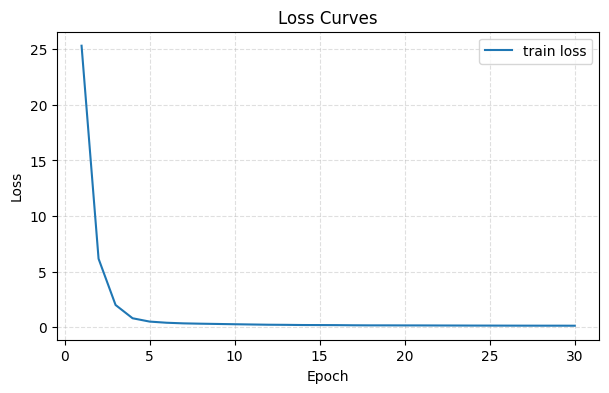

In [ ]:
# ==== کتابخانه‌ها =====
import os, json, math, time
from datetime import timedelta
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import ceil
from collections import Counter
from datasets import Dataset, DatasetDict
from transformers import AutoTokenizer, AutoModel, TrainingArguments, Trainer, TrainerCallback
from transformers.utils import logging as hf_logging
from torchcrf import CRF
import torch.nn as nn
import torch.nn.functional as F
from torch.nn import TransformerEncoder, TransformerEncoderLayer
from torch.utils.data import DataLoader
from dataclasses import dataclass
from typing import List, Dict, Any
from seqeval.metrics import classification_report, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix


torch.set_float32_matmul_precision('high')
torch.manual_seed(42); np.random.seed(42)
hf_logging.set_verbosity_error()


from google.colab import drive
drive.mount('/content/drive')


GPU_TYPE = "L4"
EPOCHS   = 30
EVAL_EVERY_N = 10
MAX_LEN = 320

BASE_DIR = "/content/drive/MyDrive/poroje"
DATA_DIR = f"{BASE_DIR}/data"


FULL_CKPT_DIR = f"{BASE_DIR}/full_ckpt_overwrite"
os.makedirs(FULL_CKPT_DIR, exist_ok=True)


LIGHT_DIR = f"{BASE_DIR}/checkpoints"
os.makedirs(LIGHT_DIR, exist_ok=True)
LIGHT_WEIGHTS_PATH = os.path.join(LIGHT_DIR, "model_light.pt")
LIGHT_STATE_JSON  = os.path.join(LIGHT_DIR, "light_state.json")


CUSTOM_TRAIN_FILE = "/content/drive/MyDrive/poroje/data/train_NER_Tech.iob"
CUSTOM_TEST_FILE  = "/content/drive/MyDrive/poroje/data/test_NER_Tech.iob"

def resolve_path(default_path, custom_value, env_key):
    p = custom_value or os.environ.get(env_key, "").strip()
    return p if p else default_path

train_file = resolve_path(f"{DATA_DIR}/train.iob", CUSTOM_TRAIN_FILE, "TRAIN_IOB")
test_file  = resolve_path(f"{DATA_DIR}/test.iob",  CUSTOM_TEST_FILE,  "TEST_IOB")
print(f"Using train file: {train_file}")
print(f"Using  test file: {test_file}")


def read_iob_file(file_path):
    sentences, labels = [], []
    tokens, tags = [], []
    with open(file_path, encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line:
                if tokens:
                    sentences.append(tokens); labels.append(tags)
                    tokens, tags = [], []
            else:
                parts = line.split()
                tok, tag = parts[0], parts[-1]
                tokens.append(tok); tags.append(tag)
        if tokens:
            sentences.append(tokens); labels.append(tags)
    return sentences, labels

train_sents, train_tags = read_iob_file(train_file)
test_sents,  test_tags  = read_iob_file(test_file)


unique_labels   = sorted({t for seq in train_tags + test_tags for t in seq})
combined_labels = ["O"] + [l for l in unique_labels if l != "O"]
label2id = {l: i for i, l in enumerate(combined_labels)}
id2label = {i: l for l, i in label2id.items()}

flat_tags = [t for seq in train_tags for t in seq]
counts    = Counter(flat_tags)
total     = sum(counts.values())
num_lbls  = len(combined_labels)
class_weights = {lbl: total/(num_lbls * counts.get(lbl, 1)) for lbl in combined_labels}
weights_tensor = torch.tensor([class_weights[lbl] for lbl in combined_labels], dtype=torch.float)
for cls in ["I-TASK", "I-DATASET", "I-TOOLS", "B-METHOD", "I-METHOD"]:
    if cls in label2id:
        weights_tensor[label2id[cls]] *= 2.0


train_examples = [{"tokens": s, "ner_tags": [label2id[t] for t in ts]} for s, ts in zip(train_sents, train_tags)]
eval_examples  = [{"tokens": s, "ner_tags": [label2id[t] for t in ts]} for s, ts in zip(test_sents,  test_tags)]
datasets = DatasetDict({"train": Dataset.from_list(train_examples),
                        "eval":  Dataset.from_list(eval_examples)})
print(datasets)


tokenizer = AutoTokenizer.from_pretrained("allenai/scibert_scivocab_cased", use_fast=True)

def tokenize_and_align_iob(ex):
    enc = tokenizer(
        ex["tokens"],
        is_split_into_words=True,
        truncation=True,
        max_length=MAX_LEN,
        add_special_tokens=False,
        return_offsets_mapping=True,
        padding=False  # پدینگ فقط در collator
    )
    word_ids = enc.word_ids()
    _ = enc.pop("offset_mapping")
    labels_aln, token_mask = [], []
    prev = None
    for wi in word_ids:
        if wi is None:
            labels_aln.append(label2id["O"]); token_mask.append(0)
        elif wi != prev:
            labels_aln.append(ex["ner_tags"][wi]); token_mask.append(1)
        else:
            tag = combined_labels[ex["ner_tags"][wi]]
            if tag.startswith("B-"): tag = tag.replace("B-", "I-")
            labels_aln.append(label2id[tag]); token_mask.append(1)
        prev = wi
    enc["labels"] = labels_aln
    enc["token_mask"] = token_mask
    return enc

tokenized = datasets.map(tokenize_and_align_iob, batched=False,
                         remove_columns=["tokens", "ner_tags"])
print(tokenized)


@dataclass
class MyTokenCollator:
    tokenizer: Any
    label_pad_token_id: int
    def __call__(self, features: List[Dict[str, Any]]) -> Dict[str, torch.Tensor]:
        labels = [f.pop("labels") for f in features]
        masks  = [f.pop("token_mask") for f in features]

        input_ids      = [torch.tensor(f["input_ids"], dtype=torch.long) for f in features]
        attention_mask = [torch.tensor(f.get("attention_mask", [1]*len(f["input_ids"])), dtype=torch.long) for f in features]
        token_type_ids = [torch.tensor(f.get("token_type_ids", [0]*len(f["input_ids"])), dtype=torch.long) for f in features]

        max_len = max(x.size(0) for x in input_ids)
        pad_len = int(ceil(max_len / 8.0) * 8)
        pad_id = self.tokenizer.pad_token_id if self.tokenizer.pad_token_id is not None else 0

        def pad_1d(seq: torch.Tensor, L: int, pad_value: int) -> torch.Tensor:
            if seq.size(0) >= L: return seq[:L]
            return torch.cat([seq, torch.full((L - seq.size(0),), pad_value, dtype=seq.dtype)])

        input_ids      = torch.stack([pad_1d(x, pad_len, pad_id) for x in input_ids], dim=0)
        attention_mask = torch.stack([pad_1d(x, pad_len, 0)     for x in attention_mask], dim=0)
        token_type_ids = torch.stack([pad_1d(x, pad_len, 0)     for x in token_type_ids], dim=0)

        def pad_list(lst, pad_val, L):
            return lst + [pad_val] * (L - len(lst)) if len(lst) < L else lst[:L]

        labels     = torch.tensor([pad_list(l, self.label_pad_token_id, pad_len) for l in labels], dtype=torch.long)
        token_mask = torch.tensor([pad_list(m, 0, pad_len) for m in masks], dtype=torch.bool)

        return {
            "input_ids": input_ids,
            "attention_mask": attention_mask,
            "token_type_ids": token_type_ids,
            "labels": labels,
            "token_mask": token_mask,
        }

data_collator = MyTokenCollator(tokenizer, label_pad_token_id=label2id["O"])


class BertCRFForTokenClassification(nn.Module):
    def __init__(self, model_name: str, num_labels: int, labels_vocab,
                 feature_extraction: bool=False,
                 class_weights: torch.Tensor=None,
                 focal_alpha: float=2.0, focal_gamma: float=3.0):
        super().__init__()
        self.bert = AutoModel.from_pretrained(model_name)
        if feature_extraction:
            for p in self.bert.parameters(): p.requires_grad = False
        self.dropout1 = nn.Dropout(0.2); self.dropout2 = nn.Dropout(0.2)
        self.word_transformer_layer = TransformerEncoderLayer(
            d_model=self.bert.config.hidden_size, nhead=8,
            dim_feedforward=self.bert.config.hidden_size*4, batch_first=True)
        self.word_transformer = TransformerEncoder(self.word_transformer_layer, num_layers=1)
        self.classifier = nn.Linear(self.bert.config.hidden_size, num_labels)
        self.crf = CRF(num_labels, batch_first=True)
        self.class_weights = class_weights; self.focal_alpha = focal_alpha
        self.focal_gamma = focal_gamma; self.labels_vocab = labels_vocab
        self._apply_bio_constraints()
    def _apply_bio_constraints(self):
        L = self.labels_vocab
        def typ(lbl): return lbl.split('-', 1)[1] if lbl!="O" else ""
        with torch.no_grad():
            for i, li in enumerate(L):
                if li.startswith("I-"): self.crf.start_transitions[i] = -1e4
                for j, lj in enumerate(L):
                    if lj.startswith("I-"):
                        ok_prev = (li == f"B-{typ(lj)}") or (li == f"I-{typ(lj)}")
                        if not ok_prev: self.crf.transitions[i, j] = -1e4
    def forward(self, input_ids, attention_mask=None, token_type_ids=None,
                labels=None, token_mask=None):
        x = self.bert(input_ids, attention_mask=attention_mask, token_type_ids=token_type_ids).last_hidden_state
        x = self.dropout1(x)
        valid_mask = token_mask.bool() if token_mask is not None else attention_mask.bool()
        x = self.word_transformer(x, src_key_padding_mask=~valid_mask)
        x = self.dropout2(x)
        emissions = self.classifier(x)
        if labels is not None:
            em = emissions.view(-1, emissions.size(-1))[valid_mask.view(-1)]
            lb = labels.view(-1)[valid_mask.view(-1)]
            ce = F.cross_entropy(em, lb, weight=(self.class_weights.to(em.device) if self.class_weights is not None else None), reduction="none")
            pt = torch.exp(-ce)
            focal = (self.focal_alpha * (1-pt)**self.focal_gamma * ce).mean()
            crf_loss = -self.crf(emissions, labels, mask=valid_mask, reduction="mean")
            return {"loss": crf_loss + focal, "logits": emissions}
        best_paths = self.crf.decode(emissions, mask=valid_mask)
        max_len = emissions.size(1)
        padded = [seq + [0]*(max_len - len(seq)) for seq in best_paths]
        return torch.tensor(padded, device=emissions.device)


class LossByEpochCallback(TrainerCallback):
    def __init__(self): self.epochs, self.losses = [], []
    def on_log(self, args, state, control, logs=None, **kwargs):
        if logs and "loss" in logs and "epoch" in logs:
            self.epochs.append(int(round(logs["epoch"]))); self.losses.append(float(logs["loss"]))

class EvalEveryNEpochsCallback(TrainerCallback):
    def __init__(self, model_ref, n, eval_dataset, data_collator, id2label):
        self.model_ref = model_ref
        self.n = n
        self.eval_dataset = eval_dataset
        self.data_collator = data_collator
        self.id2label = id2label
    def on_epoch_end(self, args, state, control, **kwargs):
        if state.epoch is None or int(state.epoch) % self.n != 0:
            return
        model = self.model_ref
        model.eval(); device = next(model.parameters()).device
        loader = DataLoader(self.eval_dataset, batch_size=32, collate_fn=self.data_collator,
                            pin_memory=True, num_workers=2)
        all_true, all_pred = [], []
        with torch.no_grad():
            for batch in loader:
                labels = batch.pop("labels"); tmask = batch["token_mask"]
                batch = {k: v.to(device) for k, v in batch.items()}
                decoded = model(**batch).cpu()
                for t_ids, p_ids, m in zip(labels, decoded, tmask):
                    st, sp = [], []
                    for t_id, p_id, mk in zip(t_ids, p_ids, m):
                        if mk:
                            st.append(self.id2label[int(t_id)])
                            sp.append(self.id2label[int(p_id)])
                    all_true.append(st); all_pred.append(sp)
        P = precision_score(all_true, all_pred); R = recall_score(all_true, all_pred); F = f1_score(all_true, all_pred)
        print(f"\n[Epoch {int(state.epoch)}] Eval -> P={P:.4f} R={R:.4f} F1={F:.4f}")

class TrainTimerCallback(TrainerCallback):
    def __init__(self, print_every=50):
        self.print_every = max(1, int(print_every))
        self.trainer = None
        self.start_time = None
        self.total_steps = None
    @staticmethod
    def _fmt(sec): return str(timedelta(seconds=int(sec)))
    def on_init_end(self, args, state, control, **kwargs):
        self.trainer = kwargs.get("trainer", None)
    def on_train_begin(self, args, state, control, **kwargs):
        self.start_time = time.time()
        if self.trainer is not None:
            steps_per_epoch = len(self.trainer.get_train_dataloader())
            self.total_steps = steps_per_epoch * int(args.num_train_epochs)
            print(f"[TIMER] steps/epoch={steps_per_epoch}, total_steps≈{self.total_steps}")
    def on_step_end(self, args, state, control, **kwargs):
        if self.start_time is None or self.total_steps is None:
            return
        gs = int(state.global_step or 0)
        if gs % self.print_every != 0 and gs != self.total_steps:
            return
        elapsed = time.time() - self.start_time
        pct = min(100.0, 100.0 * gs / max(1, self.total_steps))
        eta = (elapsed / max(1e-6, pct)) * (100.0 - pct) if pct > 0 else float('inf')
        msg = f"[TIMER] step={gs}/{self.total_steps} | {pct:5.1f}% | elapsed={self._fmt(elapsed)}"
        if math.isfinite(eta): msg += f" | ETA={self._fmt(eta)}"
        print(msg)


class FullOverwriteCheckpointCallback(TrainerCallback):
    def __init__(self, ckpt_dir: str, every_steps: int = 1000, also_on_epoch_end: bool = True):
        self.ckpt_dir = ckpt_dir
        self.every_steps = max(1, int(every_steps))
        self.also_on_epoch_end = also_on_epoch_end
        self.trainer = None
    def on_init_end(self, args, state, control, **kwargs):
        self.trainer = kwargs.get("trainer", None)
        if self.trainer is not None and not os.path.exists(os.path.join(self.ckpt_dir, "config.json")):
            self.trainer.model.config.save_pretrained(self.ckpt_dir)
            if hasattr(self.trainer, "tokenizer") and self.trainer.tokenizer is not None:
                self.trainer.tokenizer.save_pretrained(self.ckpt_dir)
    def _save_full(self, args, state):
        self.trainer.save_model(self.ckpt_dir)
        old_out = self.trainer.args.output_dir
        self.trainer.args.output_dir = self.ckpt_dir
        self.trainer.save_state()
        self.trainer.args.output_dir = old_out
        print(f"💾 [FULL CKPT] overwritten at step={state.global_step} -> {self.ckpt_dir}")
    def on_step_end(self, args, state, control, **kwargs):
        if state.global_step and state.global_step % self.every_steps == 0:
            self._save_full(args, state)
    def on_epoch_end(self, args, state, control, **kwargs):
        if self.also_on_epoch_end:
            self._save_full(args, state)


model = BertCRFForTokenClassification(
    "allenai/scibert_scivocab_cased",
    len(combined_labels),
    labels_vocab=combined_labels,
    feature_extraction=False,
    class_weights=weights_tensor,
    focal_alpha=2.0, focal_gamma=3.0
)
if os.path.exists(LIGHT_WEIGHTS_PATH):
    try:
        model.load_state_dict(torch.load(LIGHT_WEIGHTS_PATH, map_location="cpu"))
        print("ℹ️ وزن‌های سبک قبلی لود شد (برای شروع بهتر).")
    except Exception as e:
        print("⚠️ خطا در لود وزن‌های سبک:", e)

elif GPU_TYPE.upper() == "L4":
    trainer_kwargs = dict(
        num_train_epochs=EPOCHS,
        per_device_train_batch_size=16,   
        per_device_eval_batch_size=32,
        gradient_accumulation_steps=1,
        learning_rate=1e-5,
        weight_decay=0.1,
        warmup_ratio=0.3,
        bf16=True, fp16=False,            
        dataloader_num_workers=4,         
        dataloader_pin_memory=True,
        save_safetensors=True,
        
    )
else:
    raise ValueError(f"Unknown GPU_TYPE: {GPU_TYPE}")
training_args = TrainingArguments(
    output_dir=FULL_CKPT_DIR,   
    save_strategy="no",         
    logging_strategy="epoch",
    report_to=[],
    do_train=True,
    do_eval=False,
    disable_tqdm=False,
    **trainer_kwargs
)

# ===== Trainer =====
loss_cb  = LossByEpochCallback()
eval_cb  = EvalEveryNEpochsCallback(model_ref=model, n=EVAL_EVERY_N,
                                    eval_dataset=tokenized["eval"],
                                    data_collator=data_collator,
                                    id2label=id2label)
timer_cb = TrainTimerCallback(print_every=50)
full_ckpt_cb = FullOverwriteCheckpointCallback(ckpt_dir=FULL_CKPT_DIR,
                                               every_steps=1000,
                                               also_on_epoch_end=True)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized["train"],
    data_collator=data_collator,
    tokenizer=tokenizer,
    callbacks=[loss_cb, eval_cb, timer_cb, full_ckpt_cb]
)


full_ckpt_cb.trainer = trainer
timer_cb.trainer     = trainer


resume_path = FULL_CKPT_DIR if os.path.exists(os.path.join(FULL_CKPT_DIR, "trainer_state.json")) else None
if resume_path:
    print(f"✅ رزومه از چک‌پوینت ثابت: {resume_path}")
    trainer.train(resume_from_checkpoint=resume_path)
else:
    print("ℹ️ آموزش از ابتدا شروع شد.")
    trainer.train()

try:
    torch.save(model.state_dict(), LIGHT_WEIGHTS_PATH)
    with open(LIGHT_STATE_JSON, "w", encoding="utf-8") as f:
        json.dump({"last_epoch": int(EPOCHS)}, f)
    print("✅ وزن‌های سبک نهایی ذخیره شد (overwrite).")
except Exception as e:
    print("⚠️ خطا در ذخیرهٔ وزن سبک:", e)

print("\n=== ارزیابی نهایی (CRF Decode) ===")
eval_loader = DataLoader(tokenized["eval"], batch_size=64, collate_fn=data_collator,
                         pin_memory=True, num_workers=2)
model.eval(); device = next(model.parameters()).device
all_true, all_pred = [], []
with torch.no_grad():
    for batch in eval_loader:
        labels = batch.pop("labels"); tmask = batch["token_mask"]
        batch = {k: v.to(device) for k, v in batch.items()}
        decoded_ids = model(**batch).cpu()
        for true_ids, pred_ids, m in zip(labels, decoded_ids, tmask):
            st, sp = [], []
            for t_id, p_id, mk in zip(true_ids, pred_ids, m):
                if mk: st.append(id2label[int(t_id)]); sp.append(id2label[int(p_id)])
            all_true.append(st); all_pred.append(sp)

print("\n--- Classification Report")
print(classification_report(all_true, all_pred, digits=4))
print(f"\nOverall Precision: {precision_score(all_true, all_pred):.4f}")
print(f"\nOverall Recall:    {recall_score(all_true, all_pred):.4f}")
print(f"\nOverall F1:        {f1_score(all_true, all_pred):.4f}")

flat_true = [lbl for seq in all_true for lbl in seq]
flat_pred = [lbl for seq in all_pred for lbl in seq]
cm = confusion_matrix(flat_true, flat_pred, labels=combined_labels)
df_cm = pd.DataFrame(cm, index=combined_labels, columns=combined_labels)
print("\n--- Confusion Matrix ---")
print(df_cm)

# ===== نمودار Loss =====
if len(loss_cb.epochs) > 0:
    plt.figure(figsize=(7,4))
    plt.plot(loss_cb.epochs, loss_cb.losses, label="train loss")
    plt.title("Loss Curves"); plt.xlabel("Epoch"); plt.ylabel("Loss")
    plt.legend(); plt.grid(True, linestyle="--", alpha=0.4)
    plt.show()
else:
    print("⚠️ لاگ loss در دسترس نبود.")


# Roberta

In [ ]:
# ====پیش‌نیازها =====
!pip install TorchCRF pytorch-crf
!pip install --quiet transformers datasets seqeval torch evaluate torchcrf

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 3.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 8.6 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ===== کتابخانه‌ها =====
import os, json
import torch
import numpy as np
import pandas as pd
from collections import Counter
from datasets import Dataset, DatasetDict
from transformers import AutoTokenizer, AutoModel, TrainingArguments, Trainer
from transformers.trainer_utils import get_last_checkpoint  
from torchcrf import CRF
import torch.nn as nn
import torch.nn.functional as F
from torch.nn import TransformerEncoder, TransformerEncoderLayer
from torch.utils.data import DataLoader
from dataclasses import dataclass
from typing import List, Dict, Any
from seqeval.metrics import classification_report, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix

# ===== 0) نام مدل =====
MODEL_NAME = "roberta-base"   
torch.backends.cuda.matmul.allow_tf32 = True   
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# ===== 1) خواندن فایل IOB =====
def read_iob_file(file_path):
    sentences, labels = [], []
    tokens, tags = [], []
    with open(file_path, encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line:
                if tokens:
                    sentences.append(tokens)
                    labels.append(tags)
                    tokens, tags = [], []
            else:
                parts = line.split()
                tok, tag = parts[0], parts[-1]
                tokens.append(tok)
                tags.append(tag)
        if tokens:
            sentences.append(tokens)
            labels.append(tags)
    return sentences, labels

# مسیرها
train_file = "/content/drive/MyDrive/poroje/data/train_NER_Tech.iob"
test_file  = "/content/drive/MyDrive/poroje/data/test_NER_Tech.iob"

train_sents, train_tags = read_iob_file(train_file)
test_sents,  test_tags  = read_iob_file(test_file)

# ===== 2) برچسب‌ها و وزن کلاس =====
unique_labels   = sorted({t for seq in train_tags + test_tags for t in seq})
combined_labels = ["O"] + [l for l in unique_labels if l != "O"]
label2id = {l: i for i, l in enumerate(combined_labels)}
id2label = {i: l for l, i in label2id.items()}

flat_tags = [t for seq in train_tags for t in seq]
counts    = Counter(flat_tags)
total     = sum(counts.values())
num_lbls  = len(combined_labels)
class_weights = { lbl: total/(num_lbls * counts.get(lbl, 1)) for lbl in combined_labels }
weights_tensor = torch.tensor([class_weights[lbl] for lbl in combined_labels], dtype=torch.float)
for cls in ["I-TASK", "I-DATASET", "B-TECHNOLOGY", "I-TECHNOLOGY"]:
    if cls in label2id:
        weights_tensor[label2id[cls]] *= 2.0

# ===== 3) DatasetDict =====
train_examples = [{"tokens": s, "ner_tags": [label2id[t] for t in ts]} for s, ts in zip(train_sents, train_tags)]
eval_examples  = [{"tokens": s, "ner_tags": [label2id[t] for t in ts]} for s, ts in zip(test_sents,  test_tags)]
datasets = DatasetDict({
    "train": Dataset.from_list(train_examples),
    "eval":  Dataset.from_list(eval_examples),
})
print(datasets)

# ===== 4) توکنایزر و هم‌ترازی با token_mask =====
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=True,
    add_prefix_space=True   
)

MAX_LEN = 320

def tokenize_and_align_iob(ex):
    enc = tokenizer(
        ex["tokens"],
        is_split_into_words=True,
        truncation=True,
        padding="max_length",
        max_length=MAX_LEN,
        add_special_tokens=False,
        return_offsets_mapping=True
    )
    word_ids = enc.word_ids()
    _ = enc.pop("offset_mapping")

    labels_aln, token_mask = [], []
    prev = None
    for wi in word_ids:
        if wi is None:
            labels_aln.append(label2id["O"])
            token_mask.append(0)
        elif wi != prev:
            labels_aln.append(ex["ner_tags"][wi])
            token_mask.append(1)
        else:
            tag = combined_labels[ex["ner_tags"][wi]]
            if tag.startswith("B-"):
                tag = tag.replace("B-", "I-")
            labels_aln.append(label2id[tag])
            token_mask.append(1)
        prev = wi

    enc["labels"] = labels_aln
    enc["token_mask"] = token_mask
    return enc

tokenized = datasets.map(
    tokenize_and_align_iob,
    batched=False,
    remove_columns=["tokens", "ner_tags"]
)
print(tokenized)

# ===== 5) کالِیتور سفارشی =====
@dataclass
class MyTokenCollator:
    tokenizer: Any
    label_pad_token_id: int

    def __call__(self, features: List[Dict[str, Any]]) -> Dict[str, torch.Tensor]:
        labels = [f.pop("labels") for f in features]
        masks  = [f.pop("token_mask") for f in features]
        batch  = self.tokenizer.pad(features, return_tensors="pt")
        max_len = batch["input_ids"].size(1)

        def pad_to(x, pad_val, L):
            return x + [pad_val] * (L - len(x))

        batch["labels"] = torch.tensor(
            [pad_to(l, self.label_pad_token_id, max_len) for l in labels],
            dtype=torch.long
        )
        batch["token_mask"] = torch.tensor(
            [pad_to(m, 0, max_len) for m in masks],
            dtype=torch.bool
        )
        return batch

data_collator = MyTokenCollator(tokenizer, label_pad_token_id=label2id["O"])

# ===== 6) مدل با قیود BIO روی CRF + نوآوری Boundary-Aware Head =====
# نوآوری:
#  - یک head کمکی اضافه می‌شود که تشخیص می‌دهد آیا توکن "شروع موجودیت" است یا نه (B-*)
#  - boundary_loss محاسبه و به loss اصلی اضافه می‌شود:
#        loss = crf_loss + focal + beta * boundary_loss
class BertCRFForTokenClassification(nn.Module):
    def __init__(self, model_name: str, num_labels: int,
                 labels_vocab,
                 feature_extraction: bool = False,
                 class_weights: torch.Tensor = None,
                 focal_alpha: float = 2.0,
                 focal_gamma: float = 3.0,
                 boundary_beta: float = 0.3):  
        super().__init__()
        self.bert = AutoModel.from_pretrained(model_name)
        if feature_extraction:
            for p in self.bert.parameters():
                p.requires_grad = False

        self.dropout1 = nn.Dropout(0.3)
        self.dropout2 = nn.Dropout(0.3)

        self.word_transformer_layer = TransformerEncoderLayer(
            d_model=self.bert.config.hidden_size,
            nhead=8,
            dim_feedforward=self.bert.config.hidden_size * 4,
            batch_first=True
        )
        self.word_transformer = TransformerEncoder(self.word_transformer_layer, num_layers=1)

        self.classifier = nn.Linear(self.bert.config.hidden_size, num_labels)
        self.crf        = CRF(num_labels, batch_first=True)

        
        self.boundary_classifier = nn.Linear(self.bert.config.hidden_size, 2) 

        self.class_weights  = class_weights
        self.focal_alpha    = focal_alpha
        self.focal_gamma    = focal_gamma
        self.boundary_beta  = boundary_beta
        self.labels_vocab   = labels_vocab

    
        is_B_list = [1 if lbl.startswith("B-") else 0 for lbl in labels_vocab]
        self.register_buffer("is_B", torch.tensor(is_B_list, dtype=torch.long))

        self._apply_bio_constraints()

    def _apply_bio_constraints(self):
        L = self.labels_vocab
        def typ(lbl): return lbl.split('-', 1)[1] if lbl != "O" else ""
        with torch.no_grad():
            for i, li in enumerate(L):
                if li.startswith("I-"):
                    self.crf.start_transitions[i] = -1e4
                for j, lj in enumerate(L):
                    if lj.startswith("I-"):
                        ok_prev = (li == f"B-{typ(lj)}") or (li == f"I-{typ(lj)}")
                        if not ok_prev:
                            self.crf.transitions[i, j] = -1e4

    def forward(self, input_ids, attention_mask=None, token_type_ids=None,
                labels=None, token_mask=None):

        x = self.bert(
            input_ids, attention_mask=attention_mask, token_type_ids=token_type_ids
        ).last_hidden_state  

        x = self.dropout1(x)
        valid_mask = token_mask.bool() if token_mask is not None else attention_mask.bool()

        x = self.word_transformer(x, src_key_padding_mask=~valid_mask)  
        x = self.dropout2(x)

        emissions = self.classifier(x)                 
        boundary_logits = self.boundary_classifier(x)   

        if labels is not None:
            b, s, n = emissions.size()
            em = emissions.view(-1, n)[valid_mask.view(-1)]
            lb = labels.view(-1)[valid_mask.view(-1)]

            ce = F.cross_entropy(
                em, lb,
                weight=(self.class_weights.to(em.device) if self.class_weights is not None else None),
                reduction="none"
            )
            pt = torch.exp(-ce)
            focal = (self.focal_alpha * (1 - pt)**self.focal_gamma * ce).mean()

            crf_loss = -self.crf(emissions, labels, mask=valid_mask, reduction="mean")

            boundary_targets = self.is_B[labels]  

            bl = boundary_logits.view(-1, 2)[valid_mask.view(-1)]
            bt = boundary_targets.view(-1)[valid_mask.view(-1)]

            boundary_loss = F.cross_entropy(bl, bt, reduction="mean")

            total_loss = crf_loss + focal + (self.boundary_beta * boundary_loss)
            return {"loss": total_loss, "logits": emissions, "boundary_loss": boundary_loss.detach()}

        best_paths = self.crf.decode(emissions, mask=valid_mask)
        max_len = emissions.size(1)
        padded = [seq + [0]*(max_len - len(seq)) for seq in best_paths]
        return torch.tensor(padded, device=emissions.device)

# ===== 7) TrainingArguments
EPOCHS = 30
CHECKPOINT_DIR = "./temp" 
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

model = BertCRFForTokenClassification(
    MODEL_NAME,
    len(combined_labels),
    labels_vocab=combined_labels,
    feature_extraction=False,
    class_weights=weights_tensor,
    focal_alpha=2.0, focal_gamma=3.0,
    boundary_beta=0.3  
)

training_args = TrainingArguments(
    output_dir=CHECKPOINT_DIR,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=1e-5,
    weight_decay=0.1,
    warmup_ratio=0.3,
    logging_dir=os.path.join(CHECKPOINT_DIR, "logs"),
    logging_steps=100,

    save_strategy="steps",
    save_steps=200,
    save_total_limit=1,
    load_best_model_at_end=False,

    bf16=True,
    tf32=True,
    optim="adamw_torch_fused",
    dataloader_num_workers=4,
    dataloader_pin_memory=True,

   
    do_train=True,
    do_eval=True,
    report_to=[]
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["eval"],
    data_collator=data_collator,
    tokenizer=tokenizer
)
last_ckpt = get_last_checkpoint(CHECKPOINT_DIR)
trainer.train(resume_from_checkpoint=last_ckpt if last_ckpt is not None else None)

eval_results = trainer.evaluate()
print("\n=== Eval (HF; loss-based) ===")
print(eval_results)

eval_loader = DataLoader(
    tokenized["eval"],
    batch_size=16,
    collate_fn=data_collator,
    pin_memory=True,
    num_workers=2
)

model.eval()
device = next(model.parameters()).device
all_true, all_pred = [], []

with torch.no_grad():
    for batch in eval_loader:
        labels = batch.pop("labels")
        tmask  = batch["token_mask"]
        batch  = {k: v.to(device) for k, v in batch.items()}
        decoded_ids = model(**batch).cpu()

        for true_ids, pred_ids, m in zip(labels, decoded_ids, tmask):
            seq_true, seq_pred = [], []
            for t_id, p_id, mk in zip(true_ids, pred_ids, m):
                if mk:
                    seq_true.append(id2label[int(t_id)])
                    seq_pred.append(id2label[int(p_id)])
            all_true.append(seq_true)
            all_pred.append(seq_pred)

print("\n--- Classification Report")
print(classification_report(all_true, all_pred, digits=4))
print(f"\nOverall Precision: {precision_score(all_true, all_pred):.4f}")
print(f"Overall Recall:    {recall_score(all_true, all_pred):.4f}")
print(f"Overall F1:        {f1_score(all_true, all_pred):.4f}")

# ماتریس درهم‌ریختگی
flat_true = [lbl for seq in all_true for lbl in seq]
flat_pred = [lbl for seq in all_pred for lbl in seq]
cm = confusion_matrix(flat_true, flat_pred, labels=combined_labels)
df_cm = pd.DataFrame(cm, index=combined_labels, columns=combined_labels)
print("\n--- Confusion Matrix ---")
print(df_cm)


DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 55401
    })
    eval: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 13973
    })
})


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

...

Step,Training Loss
100,63.440600
200,63.018400
300,60.003900
400,54.431600
500,49.870600
600,42.983800
700,36.856100
800,30.696500
900,28.126600
1000,26.364900


You're using a RobertaTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.
You're using a RobertaTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.
You're using a RobertaTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.
You're using a RobertaTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.
You're using a RobertaTokenizerFast tokenizer. Please note that with a fast tokenize


=== Eval (HF; loss-based) ===
{'eval_loss': 8.309222221374512, 'eval_runtime': 98.647, 'eval_samples_per_second': 141.647, 'eval_steps_per_second': 8.86, 'epoch': 30.0}


You're using a RobertaTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.
You're using a RobertaTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.



--- Classification Report
              precision    recall  f1-score   support

     DATASET     0.5102    0.8268    0.6310       485
      METHOD     0.5706    0.5507    0.5605       345
      METRIC     0.9670    0.6238    0.7584      1361
       MODEL     0.9322    0.7294    0.8185      4716
        TASK     0.7334    0.8793    0.7997      1996
  TECHNOLOGY     0.8255    0.8779    0.8509      5151
       TOOLS     0.5082    0.5193    0.5137      3031

   micro avg     0.7644    0.7452    0.7547     17085
   macro avg     0.7210    0.7153    0.7047     17085
weighted avg     0.7851    0.7452    0.7567     17085


Overall Precision: 0.7644
Overall Recall:    0.7452
Overall F1:        0.7547

--- Confusion Matrix ---
                   O  B-DATASET  B-METHOD  B-METRIC  B-MODEL  B-TASK  \
O             133900         69        21        12       22     338   
B-DATASET         45        420         0         1        0      14   
B-METHOD          60          1       211         0    

# bert-base

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ===== پیش‌نیازها =====
!pip install TorchCRF pytorch-crf
!pip install --quiet transformers datasets seqeval torch evaluate torchcrf

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 2.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 6.7 MB/s eta 0:00:00


In [ ]:
# =====  کتابخانه‌ها =====
import os, json
import torch
import numpy as np
import pandas as pd
from collections import Counter
from datasets import Dataset, DatasetDict
from transformers import AutoTokenizer, AutoModel, TrainingArguments, Trainer
from transformers.trainer_utils import get_last_checkpoint  
from torchcrf import CRF
import torch.nn as nn
import torch.nn.functional as F
from torch.nn import TransformerEncoder, TransformerEncoderLayer
from torch.utils.data import DataLoader
from dataclasses import dataclass
from typing import List, Dict, Any
from seqeval.metrics import classification_report, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix

# ===== 0) نام مدل =====
MODEL_NAME = "bert-base-cased"

torch.backends.cuda.matmul.allow_tf32 = True   
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# ===== 1) خواندن فایل IOB =====
def read_iob_file(file_path):
    sentences, labels = [], []
    tokens, tags = [], []
    with open(file_path, encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line:
                if tokens:
                    sentences.append(tokens)
                    labels.append(tags)
                    tokens, tags = [], []
            else:
                parts = line.split()
                tok, tag = parts[0], parts[-1]
                tokens.append(tok)
                tags.append(tag)
        if tokens:
            sentences.append(tokens)
            labels.append(tags)
    return sentences, labels

# مسیرها
train_file = "/content/drive/MyDrive/poroje/data/train_NER_Tech.iob"
test_file  = "/content/drive/MyDrive/poroje/data/test_NER_Tech.iob"

train_sents, train_tags = read_iob_file(train_file)
test_sents,  test_tags  = read_iob_file(test_file)

# ===== 2) برچسب‌ها و وزن کلاس =====
unique_labels   = sorted({t for seq in train_tags + test_tags for t in seq})
combined_labels = ["O"] + [l for l in unique_labels if l != "O"]
label2id = {l: i for i, l in enumerate(combined_labels)}
id2label = {i: l for l, i in label2id.items()}

flat_tags = [t for seq in train_tags for t in seq]
counts    = Counter(flat_tags)
total     = sum(counts.values())
num_lbls  = len(combined_labels)
class_weights = { lbl: total/(num_lbls * counts.get(lbl, 1)) for lbl in combined_labels }
weights_tensor = torch.tensor([class_weights[lbl] for lbl in combined_labels], dtype=torch.float)

for cls in ["I-TASK", "I-DATASET", "B-TECHNOLOGY", "I-TECHNOLOGY"]:
    if cls in label2id:
        weights_tensor[label2id[cls]] *= 2.0

# ===== 3) DatasetDict =====
train_examples = [{"tokens": s, "ner_tags": [label2id[t] for t in ts]} for s, ts in zip(train_sents, train_tags)]
eval_examples  = [{"tokens": s, "ner_tags": [label2id[t] for t in ts]} for s, ts in zip(test_sents,  test_tags)]
datasets = DatasetDict({
    "train": Dataset.from_list(train_examples),
    "eval":  Dataset.from_list(eval_examples),
})
print(datasets)

# ===== 4) توکنایزر و هم‌ترازی با token_mask =====
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=True
)

MAX_LEN = 320

def tokenize_and_align_iob(ex):
    enc = tokenizer(
        ex["tokens"],
        is_split_into_words=True,
        truncation=True,
        padding="max_length",
        max_length=MAX_LEN,
        add_special_tokens=False,
        return_offsets_mapping=True
    )
    word_ids = enc.word_ids()
    _ = enc.pop("offset_mapping")

    labels_aln, token_mask = [], []
    prev = None
    for wi in word_ids:
        if wi is None:
            labels_aln.append(label2id["O"])
            token_mask.append(0)
        elif wi != prev:
            labels_aln.append(ex["ner_tags"][wi])
            token_mask.append(1)
        else:
            tag = combined_labels[ex["ner_tags"][wi]]
            if tag.startswith("B-"):
                tag = tag.replace("B-", "I-")
            labels_aln.append(label2id[tag])
            token_mask.append(1)
        prev = wi

    enc["labels"] = labels_aln
    enc["token_mask"] = token_mask
    return enc

tokenized = datasets.map(
    tokenize_and_align_iob,
    batched=False,
    remove_columns=["tokens", "ner_tags"]
)
print(tokenized)

# ===== 5) کالِیتور سفارشی =====
@dataclass
class MyTokenCollator:
    tokenizer: Any
    label_pad_token_id: int

    def __call__(self, features: List[Dict[str, Any]]) -> Dict[str, torch.Tensor]:
        labels = [f.pop("labels") for f in features]
        masks  = [f.pop("token_mask") for f in features]
        batch  = self.tokenizer.pad(features, return_tensors="pt")
        max_len = batch["input_ids"].size(1)

        def pad_to(x, pad_val, L):
            return x + [pad_val] * (L - len(x))

        batch["labels"] = torch.tensor(
            [pad_to(l, self.label_pad_token_id, max_len) for l in labels],
            dtype=torch.long
        )
        batch["token_mask"] = torch.tensor(
            [pad_to(m, 0, max_len) for m in masks],
            dtype=torch.bool
        )
        return batch

data_collator = MyTokenCollator(tokenizer, label_pad_token_id=label2id["O"])

# ===== 6) مدل با قیود BIO روی CRF + نوآوری Boundary-Aware Head =====
# نوآوری:
#  - head کمکی برای تشخیص "شروع موجودیت" (B-*) اضافه شده
#  - boundary_loss به loss اصلی اضافه می‌شود:
#        loss = crf_loss + focal + beta * boundary_loss
class BertCRFForTokenClassification(nn.Module):
    def __init__(self, model_name: str, num_labels: int,
                 labels_vocab,
                 feature_extraction: bool = False,
                 class_weights: torch.Tensor = None,
                 focal_alpha: float = 2.0,
                 focal_gamma: float = 3.0,
                 boundary_beta: float = 0.3):   
        super().__init__()
        self.bert = AutoModel.from_pretrained(model_name)
        if feature_extraction:
            for p in self.bert.parameters():
                p.requires_grad = False

        self.dropout1 = nn.Dropout(0.3)
        self.dropout2 = nn.Dropout(0.3)

        self.word_transformer_layer = TransformerEncoderLayer(
            d_model=self.bert.config.hidden_size,
            nhead=8,
            dim_feedforward=self.bert.config.hidden_size * 4,
            batch_first=True
        )
        self.word_transformer = TransformerEncoder(self.word_transformer_layer, num_layers=1)

        self.classifier = nn.Linear(self.bert.config.hidden_size, num_labels)
        self.crf        = CRF(num_labels, batch_first=True)

        
        self.boundary_classifier = nn.Linear(self.bert.config.hidden_size, 2)  

        self.class_weights  = class_weights
        self.focal_alpha    = focal_alpha
        self.focal_gamma    = focal_gamma
        self.boundary_beta  = boundary_beta
        self.labels_vocab   = labels_vocab

       
        is_B_list = [1 if lbl.startswith("B-") else 0 for lbl in labels_vocab]
        self.register_buffer("is_B", torch.tensor(is_B_list, dtype=torch.long))

        self._apply_bio_constraints()

    def _apply_bio_constraints(self):
        L = self.labels_vocab
        def typ(lbl): return lbl.split('-', 1)[1] if lbl != "O" else ""
        with torch.no_grad():
            for i, li in enumerate(L):
                if li.startswith("I-"):
                    self.crf.start_transitions[i] = -1e4
                for j, lj in enumerate(L):
                    if lj.startswith("I-"):
                        ok_prev = (li == f"B-{typ(lj)}") or (li == f"I-{typ(lj)}")
                        if not ok_prev:
                            self.crf.transitions[i, j] = -1e4

    def forward(self, input_ids, attention_mask=None, token_type_ids=None,
                labels=None, token_mask=None):

        x = self.bert(
            input_ids, attention_mask=attention_mask, token_type_ids=token_type_ids
        ).last_hidden_state  

        x = self.dropout1(x)
        valid_mask = token_mask.bool() if token_mask is not None else attention_mask.bool()

        x = self.word_transformer(x, src_key_padding_mask=~valid_mask)  
        x = self.dropout2(x)

        emissions = self.classifier(x)                 
        boundary_logits = self.boundary_classifier(x)  

        if labels is not None:
            
            b, s, n = emissions.size()
            em = emissions.view(-1, n)[valid_mask.view(-1)]
            lb = labels.view(-1)[valid_mask.view(-1)]

            ce = F.cross_entropy(
                em, lb,
                weight=(self.class_weights.to(em.device) if self.class_weights is not None else None),
                reduction="none"
            )
            pt = torch.exp(-ce)
            focal = (self.focal_alpha * (1 - pt)**self.focal_gamma * ce).mean()

            
            crf_loss = -self.crf(emissions, labels, mask=valid_mask, reduction="mean")
            
            boundary_targets = self.is_B[labels]  

            bl = boundary_logits.view(-1, 2)[valid_mask.view(-1)]
            bt = boundary_targets.view(-1)[valid_mask.view(-1)]
            boundary_loss = F.cross_entropy(bl, bt, reduction="mean")

            total_loss = crf_loss + focal + (self.boundary_beta * boundary_loss)
            return {"loss": total_loss, "logits": emissions, "boundary_loss": boundary_loss.detach()}

        # ===== inference (decode با CRF) =====
        best_paths = self.crf.decode(emissions, mask=valid_mask)
        max_len = emissions.size(1)
        padded = [seq + [0]*(max_len - len(seq)) for seq in best_paths]
        return torch.tensor(padded, device=emissions.device)

# ===== 7) TrainingArguments 
EPOCHS = 30
CHECKPOINT_DIR = "./temp"  
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

model = BertCRFForTokenClassification(
    MODEL_NAME,
    len(combined_labels),
    labels_vocab=combined_labels,
    feature_extraction=False,
    class_weights=weights_tensor,
    focal_alpha=2.0, focal_gamma=3.0,
    boundary_beta=0.3   
)

training_args = TrainingArguments(
    output_dir=CHECKPOINT_DIR,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=1e-5,
    weight_decay=0.1,
    warmup_ratio=0.3,
    logging_dir=os.path.join(CHECKPOINT_DIR, "logs"),
    logging_steps=100,

    save_strategy="steps",
    save_steps=200,
    save_total_limit=1,
    load_best_model_at_end=False,

    bf16=True,
    tf32=True,
    optim="adamw_torch_fused",
    dataloader_num_workers=4,
    dataloader_pin_memory=True,

    do_train=True,
    do_eval=True,
    report_to=[]
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["eval"],
    data_collator=data_collator,
    tokenizer=tokenizer
)

last_ckpt = get_last_checkpoint(CHECKPOINT_DIR)
trainer.train(resume_from_checkpoint=last_ckpt if last_ckpt is not None else None)

eval_results = trainer.evaluate()
print("\n=== Eval (HF; loss-based) ===")
print(eval_results)

eval_loader = DataLoader(
    tokenized["eval"],
    batch_size=16,
    collate_fn=data_collator,
    pin_memory=True,
    num_workers=2
)

model.eval()
device = next(model.parameters()).device
all_true, all_pred = [], []

with torch.no_grad():
    for batch in eval_loader:
        labels = batch.pop("labels")
        tmask  = batch["token_mask"]
        batch  = {k: v.to(device) for k, v in batch.items()}
        decoded_ids = model(**batch).cpu()

        for true_ids, pred_ids, m in zip(labels, decoded_ids, tmask):
            seq_true, seq_pred = [], []
            for t_id, p_id, mk in zip(true_ids, pred_ids, m):
                if mk:
                    seq_true.append(id2label[int(t_id)])
                    seq_pred.append(id2label[int(p_id)])
            all_true.append(seq_true)
            all_pred.append(seq_pred)

print("\n--- Classification Report")
print(classification_report(all_true, all_pred, digits=4))
print(f"\nOverall Precision: {precision_score(all_true, all_pred):.4f}")
print(f"Overall Recall:    {recall_score(all_true, all_pred):.4f}")
print(f"Overall F1:        {f1_score(all_true, all_pred):.4f}")

# ماتریس درهم‌ریختگی
flat_true = [lbl for seq in all_true for lbl in seq]
flat_pred = [lbl for seq in all_pred for lbl in seq]
cm = confusion_matrix(flat_true, flat_pred, labels=combined_labels)
df_cm = pd.DataFrame(cm, index=combined_labels, columns=combined_labels)
print("\n--- Confusion Matrix ---")
print(df_cm)


DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 55401
    })
    eval: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 13973
    })
})


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

...

Step,Training Loss
100,63.744300
200,61.949600
300,56.928600
400,49.071200
500,44.520900
600,39.219700
700,35.838800
800,31.925100
900,29.470200
1000,27.824400


You're using a BertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.
You're using a BertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.
You're using a BertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.
You're using a BertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.



=== Eval (HF; loss-based) ===
{'eval_loss': 8.841450691223145, 'eval_runtime': 98.8081, 'eval_samples_per_second': 141.416, 'eval_steps_per_second': 8.845, 'epoch': 30.0}


You're using a BertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.
You're using a BertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.



--- Classification Report
              precision    recall  f1-score   support

     DATASET     0.4463    0.8309    0.5807       485
      METHOD     0.5679    0.5333    0.5501       345
      METRIC     0.9618    0.6289    0.7606      1361
       MODEL     0.9080    0.8959    0.9019      4716
        TASK     0.7295    0.8768    0.7964      1996
  TECHNOLOGY     0.7498    0.8835    0.8112      5151
       TOOLS     0.4932    0.2768    0.3546      3031

   micro avg     0.7561    0.7497    0.7529     17085
   macro avg     0.6938    0.7037    0.6793     17085
weighted avg     0.7502    0.7497    0.7376     17085


Overall Precision: 0.7561
Overall Recall:    0.7497
Overall F1:        0.7529

--- Confusion Matrix ---
                   O  B-DATASET  B-METHOD  B-METRIC  B-MODEL  B-TASK  \
O             149709         62        33         6       65     169   
B-DATASET         38        425         0         1        1      14   
B-METHOD          55          1       209         0    